# 05 · Category counts: chi-square versus Fisher’s exact
**Insight:** a large-sample approximation needs enough information in the cells—not just a large total sample.

Compare two independent campaigns × converted/did not convert (**2×2 tables**). Under the simulated null, both campaigns have the same conversion probability. We measure how often Pearson chi-square and Fisher’s exact produce a false alarm. We also show Yates-corrected chi-square so the approximation is not confused with software defaults.

**Scope:** independent binary outcomes; each person contributes to one cell only. Fixed group sizes, random conversion counts. No paired measurements, follow-up comparisons, or larger-table exact tests in this notebook. All tests use alpha 0.05; Fisher’s is two-sided. These are simulated counts, not real campaign evidence.

In [1]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 20261129
REPETITIONS = 20_000
ALPHA = .05
OUT = Path("outputs/05-chi-square-and-fisher")
OUT.mkdir(parents=True, exist_ok=True)
scenarios = [
    dict(scenario="Plentiful counts", n_a=500, n_b=500, probability=.30),
    dict(scenario="Sparse counts", n_a=20, n_b=100, probability=.02),
]
settings_table = pd.DataFrame(scenarios)
settings_table["expected_conversions_a_under_model"] = settings_table.n_a*settings_table.probability
settings_table["expected_conversions_b_under_model"] = settings_table.n_b*settings_table.probability
settings_table.to_csv(OUT / "scenario_settings.csv", index=False)
display(settings_table)

,scenario,n_a,n_b,probability,expected_conversions_a_under_model,expected_conversions_b_under_model
0,Plentiful counts,500,500,0.30,150.0,150.0
1,Sparse counts,20,100,0.02,0.4,2.0


## 1 · What chi-square compares
Under independence, **expected count = row total × column total / grand total**. Pearson’s statistic adds **(observed − expected)² / expected** across cells. Its p-value uses a chi-square reference distribution with (rows−1)(columns−1) degrees of freedom: **1 here**.

It can handle larger categorical tables with one omnibus test, but does not identify which categories differ or correct separate follow-up comparisons. Counts need not be normally distributed. The reference distribution is an asymptotic approximation.

The warning concerns **expected**, not simply observed, counts. “About 5 per expected cell” is a useful introductory warning, not a universal cutoff. The table’s fitted expected counts use its observed margins; these differ from the population-model expectations in the setup above.

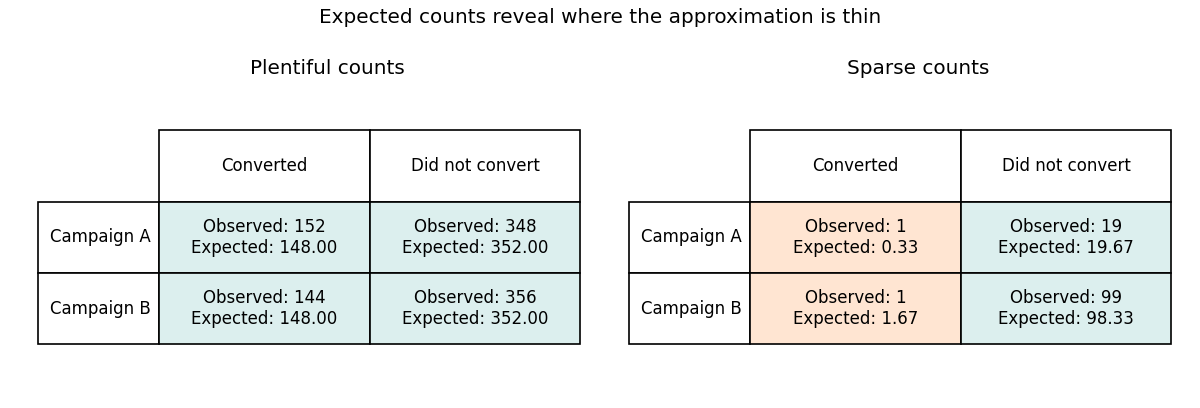

In [2]:
# Constructed teaching tables, not selected simulation results.
examples = {
    "Plentiful counts": np.array([[152, 348], [144, 356]]),
    "Sparse counts": np.array([[1, 19], [1, 99]]),
}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
example_rows = []
for ax, (name, observed) in zip(axes, examples.items()):
    expected = stats.contingency.expected_freq(observed)
    ax.axis("off")
    cell_text = [[f"Observed: {observed[i,j]}\nExpected: {expected[i,j]:.2f}" for j in range(2)] for i in range(2)]
    table = ax.table(cellText=cell_text, rowLabels=["Campaign A", "Campaign B"],
                     colLabels=["Converted", "Did not convert"], cellLoc="center", loc="center", bbox=[.18,.15,.8,.7])
    table.auto_set_font_size(False); table.set_fontsize(10)
    for i in range(2):
        for j in range(2):
            table[i+1,j].set_facecolor("#ffe5d2" if expected[i,j]<5 else "#dcefee")
            example_rows.append(dict(scenario=name, group="AB"[i], outcome=j,
                                     observed=int(observed[i,j]), expected=expected[i,j]))
    ax.set_title(name)
fig.suptitle("Expected counts reveal where the approximation is thin")
fig.tight_layout()
fig.savefig(OUT / "observed_expected_tables.png", dpi=180)
plt.show()
pd.DataFrame(example_rows).to_csv(OUT / "illustrative_tables.csv", index=False)

## 2 · What Fisher calculates instead
Fisher’s test conditions on the observed row and column totals. Under no association, the count in the top-left cell follows a **hypergeometric distribution**. The two-sided p-value sums probabilities of tables with those margins that are no more probable than the observed table (the SciPy convention used here).

It avoids the chi-square approximation. “Exact” does **not** mean its false-alarm rate is exactly 5%: attainable p-values are discrete, so Fisher can be conservative. It also does not guarantee higher power. Conditioning on the margins gives valid null inference for this independent-binomial design even though conversion totals were not fixed before sampling.

**Implementation choices:** report Pearson chi-square with `correction=False`, the Yates continuity-corrected variant with `correction=True` (SciPy’s usual 2×2 default), and Fisher. If a simulated table has zero conversions in both groups (or everyone converts), there is no outcome variation. Chi-square is undefined because a column’s expected counts are zero. Retain that experiment as **no rejection**, recording how often it happens, rather than silently dropping it; Fisher returns p=1.

In [3]:
rng = np.random.default_rng(SEED)
metric_rows, diagnostic_rows, trial_frames = [], [], []
for s in scenarios:
    a = rng.binomial(s["n_a"], s["probability"], REPETITIONS)
    b = rng.binomial(s["n_b"], s["probability"], REPETITIONS)
    pairs = np.column_stack([a,b])
    unique, inverse = np.unique(pairs, axis=0, return_inverse=True)
    cached = []
    for aa, bb in unique:
        observed = np.array([[aa, s["n_a"]-aa], [bb, s["n_b"]-bb]])
        expected = stats.contingency.expected_freq(observed)
        degenerate = aa+bb in (0, s["n_a"]+s["n_b"])
        pearson = np.nan if degenerate else stats.chi2_contingency(observed, correction=False).pvalue
        yates = np.nan if degenerate else stats.chi2_contingency(observed, correction=True).pvalue
        fisher = stats.fisher_exact(observed, alternative="two-sided").pvalue
        cached.append([pearson,yates,fisher,expected.min(),float(degenerate)])
    result = np.array(cached)[inverse]
    degenerate = result[:,4].astype(bool)
    diagnostic_rows.append(dict(scenario=s["scenario"], zero_variation_pct=100*degenerate.mean(),
                               expected_cell_below_5_pct=100*(result[:,3]<5).mean()))
    for idx, test in enumerate(["Pearson chi-square", "Yates chi-square", "Fisher exact"]):
        pv = result[:,idx]
        rejected = pv < ALPHA  # NaN (undefined) yields False; kept in denominator.
        count = int(rejected.sum())
        ci = stats.binomtest(count, REPETITIONS).proportion_ci(method="wilson")
        metric_rows.append(dict(scenario=s["scenario"], test=test, repetitions=REPETITIONS,
            false_positives=count, false_positive_pct=100*rejected.mean(),
            mc_low_pct=100*ci.low, mc_high_pct=100*ci.high,
            undefined_test_pct=100*np.isnan(pv).mean()))
    trial_frames.append(pd.DataFrame(dict(scenario=s["scenario"], conversions_a=a, conversions_b=b,
        pearson_p=result[:,0], yates_p=result[:,1], fisher_p=result[:,2],
        min_expected_count=result[:,3], zero_outcome_variation=degenerate)))
    assert np.all(result[~degenerate,:3]>=0) and np.all(result[~degenerate,:3]<=1)
    assert np.all(result[degenerate,2] == 1)
metrics = pd.DataFrame(metric_rows)
diagnostics = pd.DataFrame(diagnostic_rows)
metrics.to_csv(OUT / "metrics.csv", index=False)
diagnostics.to_csv(OUT / "diagnostics.csv", index=False)
pd.concat(trial_frames, ignore_index=True).to_csv(OUT / "trials.csv", index=False)
display(metrics.round(3))
display(diagnostics.round(3))

,scenario,test,repetitions,false_positives,false_positive_pct,mc_low_pct,mc_high_pct,undefined_test_pct
0,Plentiful counts,Pearson chi-square,20000,989,4.945,4.653,5.254,0.00
1,Plentiful counts,Yates chi-square,20000,837,4.185,3.916,4.471,0.00
2,Plentiful counts,Fisher exact,20000,838,4.190,3.921,4.477,0.00
3,Sparse counts,Pearson chi-square,20000,1236,6.180,5.855,6.522,9.06
4,Sparse counts,Yates chi-square,20000,249,1.245,1.100,1.408,9.06
5,Sparse counts,Fisher exact,20000,249,1.245,1.100,1.408,0.00


,scenario,zero_variation_pct,expected_cell_below_5_pct
0,Plentiful counts,0.00,0.0
1,Sparse counts,9.06,100.0


## 3 · Does the false-alarm rate stay controlled?
The target is 5%; lower is conservative, not automatically “better.” Error bars are 95% Wilson Monte Carlo intervals. The sparse scenario intentionally combines rare outcomes and unequal group sizes to illustrate a setting where Pearson’s approximation can be inaccurate; it is not a claim about every sparse table. Sparse cases can also make chi-square conservative. This notebook measures calibration, not power.

Plentiful counts | Pearson chi-square: 4.95% false positives
Plentiful counts | Yates chi-square: 4.18% false positives
Plentiful counts | Fisher exact: 4.19% false positives
Sparse counts | Pearson chi-square: 6.18% false positives
Sparse counts | Yates chi-square: 1.24% false positives
Sparse counts | Fisher exact: 1.24% false positives


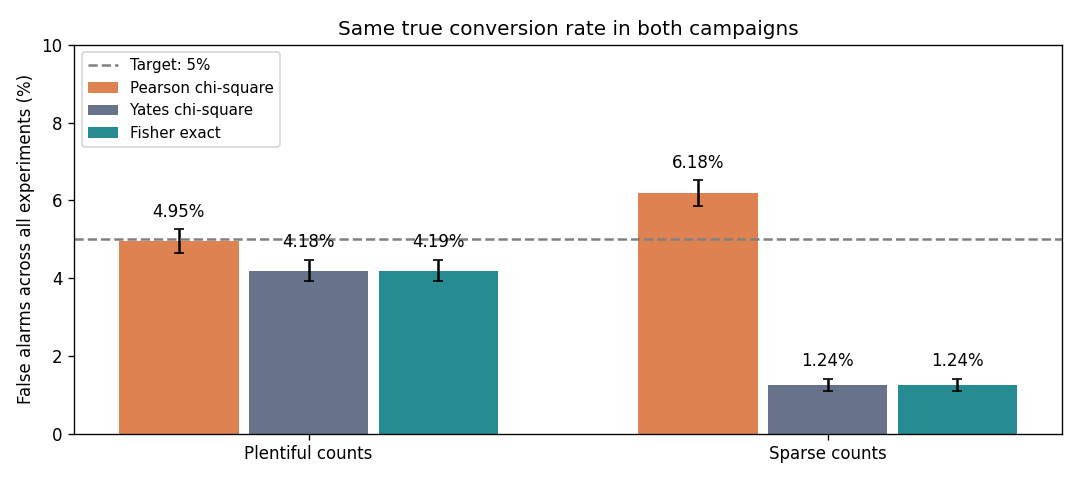

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(2)
styles = [("Pearson chi-square", -.25, "#df8252"),
          ("Yates chi-square", 0, "#66738a"), ("Fisher exact", .25, "#268c91")]
for test, offset, color in styles:
    sub = metrics[metrics.test == test]
    y = sub.false_positive_pct.to_numpy()
    err = np.maximum(0,np.vstack([y-sub.mc_low_pct.to_numpy(),sub.mc_high_pct.to_numpy()-y]))
    bars = ax.bar(x+offset,y,.23,color=color,label=test,yerr=err,capsize=3)
    ax.bar_label(bars,labels=[f"{v:.2f}%" for v in y],padding=5)
ax.axhline(5,color="gray",linestyle="--",label="Target: 5%")
ax.set_xticks(x,[s["scenario"] for s in scenarios])
ax.set(ylabel="False alarms across all experiments (%)",ylim=(0,10),title="Same true conversion rate in both campaigns")
ax.legend(fontsize=9,loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "false_positive_rates.png",dpi=180)
plt.show()
# Check the Pearson statistic directly against its definition.
observed = examples["Sparse counts"]
expected = stats.contingency.expected_freq(observed)
assert np.isclose(((observed-expected)**2/expected).sum(),
                  stats.chi2_contingency(observed,correction=False).statistic)
# Verify Fisher's two-sided p-value via explicit fixed-margin enumeration.
M = observed.sum(); success_total = observed[:,0].sum(); row_a = observed[0].sum()
lo,hi = stats.hypergeom.support(M,success_total,row_a)
counts = np.arange(lo,hi+1)
prob = stats.hypergeom.pmf(counts,M,success_total,row_a)
observed_prob = stats.hypergeom.pmf(observed[0,0],M,success_total,row_a)
manual_fisher = prob[prob <= observed_prob*(1+1e-12)].sum()
assert np.isclose(manual_fisher,stats.fisher_exact(observed).pvalue)
settings = dict(seed=SEED,repetitions=REPETITIONS,alpha=ALPHA,scenarios=scenarios,
    pearson_correction=False,yates_correction=True,fisher_alternative="two-sided",
    degenerate_policy="Chi-square undefined, no rejection; retained in denominator",
    python=platform.python_version(),numpy=np.__version__,scipy=scipy.__version__)
(OUT / "settings.json").write_text(json.dumps(settings,indent=2))
for _, r in metrics.iterrows():
    print(f'{r.scenario} | {r.test}: {r.false_positive_pct:.2f}% false positives')

## Takeaway
**Chi-square is a useful general count-table test, but its p-value relies on an approximation. Fisher’s supplies an exact conditional calculation for sparse 2×2 tables.** Check expected cell counts, not just total sample size.

The correction setting matters: Pearson and Yates are not interchangeable labels for the same computation. Neither Yates nor Fisher promises a rate closer to 5% in every design; discreteness can make their decisions conservative. No automatic threshold rule or universal winner is established by these two settings.

A non-significant result does not prove equal conversion rates. A significant overall categorical association does not identify which categories differ in a larger table. Larger-table testing and paired categorical outcomes remain outside this notebook.

**Review prompt:** Why can 120 observations still be too sparse for the chi-square approximation when only 2% are expected to convert?

## Website presentation brief
**Headline:** “Enough people does not always mean enough information in each cell.”

1. Show the 2×2 campaign table; distinguish observed counts from fitted expected counts. Highlight small expected cells. Use the labelled constructed examples, not a supposedly representative or cherry-picked significant sample.
2. Explain Pearson’s observed-versus-expected discrepancy with one cell before revealing the full sum. Keep degrees of freedom in optional detail. It is an association test, not a multiple-comparison correction.
3. Switch between plentiful and sparse simulation settings, showing n per group, the shared true conversion probability, and expected conversions under the population model.
4. Compare false-alarm rates with a 5% line and Monte Carlo intervals. Lead with Pearson versus Fisher; retain Yates as a clearly labelled additional series so users can understand software defaults. Source displayed values from saved metrics.
5. Explain Fisher’s fixed-margin probability calculation briefly: no large-sample approximation, but exact does not mean exactly 5% false alarms or superior power.

Include the proportion of zero-outcome-variation experiments and their treatment in optional details. The metric includes every simulated experiment. Do not portray the sparse scenario as showing that every chi-square implementation always inflates errors. No website or paired extension is implemented here.
